# An activity-list CSV: weekly training volume

Exports of workouts (Strava's, Garmin's, Polar's, COROS's, once FIT or TCX files are turned into rows) reduce to one row per activity. This notebook sums minutes and distance per week and activity type and charts the weekly volume.

**The input here is synthetic** (`activities-synthetic.csv` from [https://aifitnessapi.com/own-your-data](https://aifitnessapi.com/own-your-data#notebooks)), generated from a fixed seed. Its column names are **ours, not any vendor's**. Set `CSV` and `COLUMNS` for your own file.

In [1]:
import os, urllib.request

def local_or_download(path, url):
    """Use the file next to this notebook if it is there (a clone of the repo),
    otherwise download the synthetic sample once (Colab)."""
    if os.path.exists(path):
        return path
    name = os.path.basename(path)
    if not os.path.exists(name):
        urllib.request.urlretrieve(url, name)
    return name

CSV = local_or_download("data/activities-synthetic.csv",
                        "https://aifitnessapi.com/notebooks/data/activities-synthetic.csv")
COLUMNS = {"start_time": "start_time", "activity_type": "activity_type",
           "duration_min": "duration_min", "distance_km": "distance_km", "avg_hr_bpm": "avg_hr_bpm"}

In [2]:
import pandas as pd
a = pd.read_csv(CSV, comment="#").rename(columns={v: k for k, v in COLUMNS.items()})
# Keep the local wall-clock time as written: the offset is dropped, not converted.
a["start"] = pd.to_datetime(a["start_time"].str[:19])
a["week"] = a["start"].dt.to_period("W-SUN").dt.start_time
a.head()

,start_time,activity_type,duration_min,distance_km,avg_hr_bpm,active_kcal,start,week
0,2026-06-01 19:48:00 -0700,Running,30.1,4.60,145,240,2026-06-01 19:48:00,2026-06-01
1,2026-06-03 18:44:00 -0700,TraditionalStrengthTraining,48.2,NaN,127,514,2026-06-03 18:44:00,2026-06-01
2,2026-06-05 18:02:00 -0700,Running,29.8,5.17,130,271,2026-06-05 18:02:00,2026-06-01
3,2026-06-06 19:01:00 -0700,Cycling,28.6,13.65,147,203,2026-06-06 19:01:00,2026-06-01
4,2026-06-08 18:50:00 -0700,Running,63.4,10.99,136,631,2026-06-08 18:50:00,2026-06-08


In [3]:
a.groupby("activity_type").agg(sessions=("start", "size"), minutes=("duration_min", "sum"),
                               km=("distance_km", "sum"), avg_hr=("avg_hr_bpm", "mean")).round(1)

,sessions,minutes,km,avg_hr
activity_type,,,,
Cycling,17,763.9,341.2,138.8
Running,35,1729.4,288.8,134.7
TraditionalStrengthTraining,17,761.8,0.0,134.8


## Weekly minutes by activity

A pivot table with weeks as rows and activity types as columns, then a stacked bar chart.

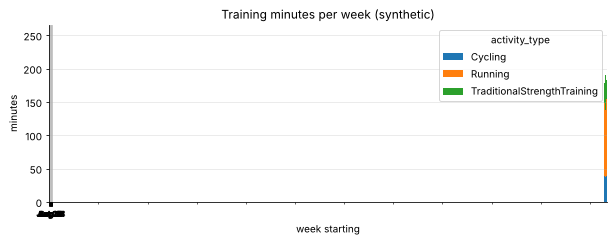

activity_type,Cycling,Running,TraditionalStrengthTraining
week,,,
2026-06-01,29.0,60.0,48.0
2026-06-08,37.0,123.0,55.0
2026-06-15,42.0,122.0,28.0
2026-06-22,61.0,124.0,69.0
2026-06-29,39.0,109.0,30.0
2026-07-06,69.0,117.0,37.0
2026-07-13,50.0,65.0,32.0
2026-07-20,37.0,61.0,66.0
2026-07-27,61.0,78.0,42.0


In [4]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 3.2), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 72})

weekly = a.pivot_table(index="week", columns="activity_type", values="duration_min", aggfunc="sum").fillna(0)
ax = weekly.plot(kind="bar", stacked=True, width=0.85, title="Training minutes per week (synthetic)")
ax.set_xticks(range(len(weekly)))
ax.set_xticklabels([d.strftime("%b %d") for d in weekly.index], rotation=0, fontsize=8)
ax.set_ylabel("minutes"); ax.set_xlabel("week starting")
plt.show()
weekly.round(0)

## Load change week to week

A common rule of thumb compares each week with the average of the previous four. Here it is computed, not judged: what counts as too fast an increase is a coaching question.

In [5]:
total = weekly.sum(axis=1)
ratio = (total / total.shift(1).rolling(4).mean()).round(2)
pd.DataFrame({"minutes": total.round(0), "vs previous 4-week mean": ratio})

,minutes,vs previous 4-week mean
week,,
2026-06-01,137.0,NaN
2026-06-08,214.0,NaN
2026-06-15,191.0,NaN
2026-06-22,254.0,NaN
2026-06-29,178.0,0.90
2026-07-06,223.0,1.06
2026-07-13,146.0,0.69
2026-07-20,164.0,0.82
2026-07-27,182.0,1.02
